# Linear Regression Lab (SciKit-Learn) — Salary Dataset
## Student Notebook (Fill in the Blanks)

This notebook is available in the codebase that comes along with the book. In this exercise, you will learn how to implement Linear Regression using Scikit-learn, how to build a Machine Learning regression model, and how to draw relevant plots.

**Dataset:** Salary dataset from the codebase (example: `Salary_Data.csv`).

Follow the step-by-step instructions and complete each cell.

## Step 1 — Import Required Libraries
**Task:** Complete the imports.

In [1]:
# Step 1: Import required libraries
import numpy as np                      # numerical operations
import pandas as pd                     # data loading and manipulation
import matplotlib.pyplot as plt         # plotting

from sklearn.model_selection import train_test_split   # split data into train/test
from sklearn.linear_model import LinearRegression      # the regression model
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score  # evaluation metrics

## Step 2 — Load the Salary Dataset
**Task:** Read the CSV file from the codebase and display top rows.

In [2]:
# Step 2: Load the dataset and preview the first 5 rows
df = pd.read_csv("Salary_Data.csv")
df.head()

,YearsExperience,Salary
0,1.1,39343.0
1,1.3,46205.0
2,1.5,37731.0
3,2.0,43525.0
4,2.2,39891.0


## Step 3 — Explore the Dataset
**Task:** Print shape, columns, missing values, and statistics.

In [3]:
# Step 3: Explore the dataset
# Number of rows and columns
print("Shape:", df.shape)

# Column names
print("\nColumns:", df.columns.tolist())

# Count of missing values in each column
print("\nMissing values:\n", df.isnull().sum())

# Summary statistics (count, mean, std, min, quartiles, max)
df.describe()

Shape: (30, 2)

Columns: ['YearsExperience', 'Salary']

Missing values:
 YearsExperience    0
Salary             0
dtype: int64


,YearsExperience,Salary
count,30.000000,30.000000
mean,5.313333,76003.000000
std,2.837888,27414.429785
min,1.100000,37731.000000
25%,3.200000,56720.750000
50%,4.700000,65237.000000
75%,7.700000,100544.750000
max,10.500000,122391.000000


### Step 3b — Data Exploration Charts
**Task:** Visualize the distribution of each variable and their relationship.

Correlation:
                  YearsExperience    Salary
YearsExperience         1.000000  0.978242
Salary                  0.978242  1.000000


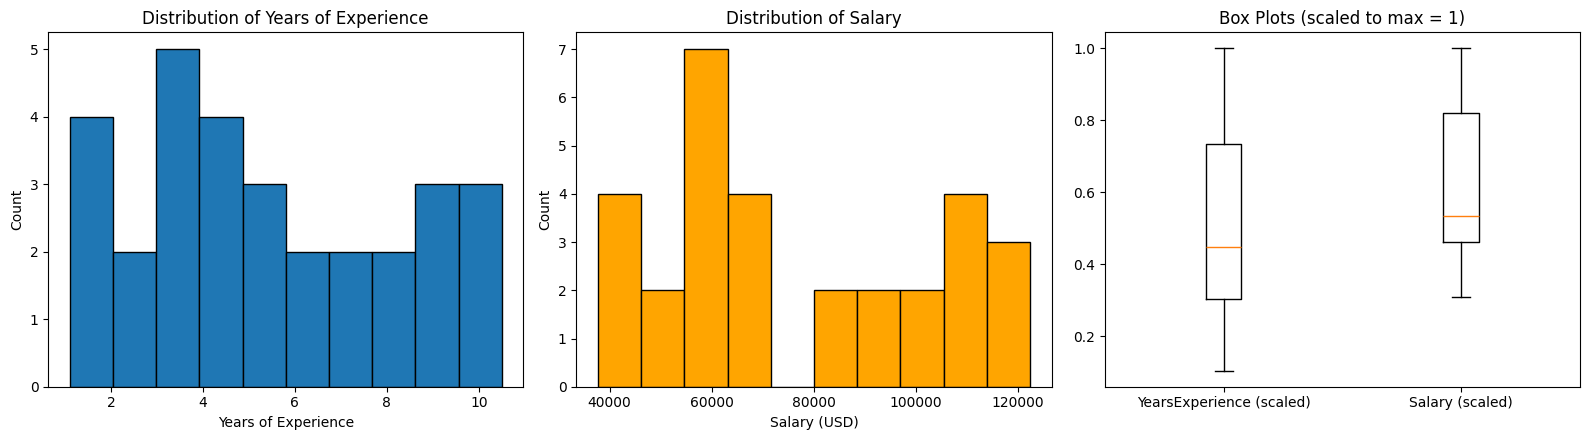

In [4]:
# Step 3b: Data exploration charts
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Distribution of experience
axes[0].hist(df["YearsExperience"], bins=10, edgecolor="black")
axes[0].set_title("Distribution of Years of Experience")
axes[0].set_xlabel("Years of Experience")
axes[0].set_ylabel("Count")

# Distribution of salary
axes[1].hist(df["Salary"], bins=10, edgecolor="black", color="orange")
axes[1].set_title("Distribution of Salary")
axes[1].set_xlabel("Salary (USD)")
axes[1].set_ylabel("Count")

# Box plot to spot outliers
axes[2].boxplot([df["YearsExperience"] / df["YearsExperience"].max(),
                 df["Salary"] / df["Salary"].max()],
                labels=["YearsExperience (scaled)", "Salary (scaled)"])
axes[2].set_title("Box Plots (scaled to max = 1)")

plt.tight_layout()
plt.show()

# Correlation between the two columns
print("Correlation:\n", df.corr())

## Step 4 — Define Features (X) and Target (y)
**Task:** Use `YearsExperience` as X and `Salary` as y. Remember: X must be 2D.

In [5]:
# Step 4: Define features (X) and target (y)
X = df[["YearsExperience"]]     # double brackets keep X as a 2D DataFrame (required by sklearn)
y = df["Salary"]                # target is a 1D Series

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (30, 1)
y shape: (30,)


## Step 5 — Split Dataset into Training and Test Sets
**Task:** Use `train_test_split` with a test size and random state.

In [6]:
# Step 5: Split into training (80%) and test (20%) sets
# random_state makes the split reproducible
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape, "X_test:", X_test.shape)

X_train: (24, 1) X_test: (6, 1)


## Step 6 — Train the Linear Regression Model
**Task:** Create and fit the model. Print intercept and coefficient.

In [7]:
# Step 6: Create and train the Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)          # learn intercept and slope from the training data

print("Intercept:", model.intercept_)
print("Coefficient:", model.coef_[0])

Intercept: 25321.583011776813
Coefficient: 9423.815323030976


## Step 7 — Make Predictions
**Task:** Predict salary for the test set and display first 5 rows of results.

In [8]:
# Step 7: Predict salaries for the test set and compare with actual values
y_pred = model.predict(X_test)

pd.DataFrame({
    "YearsExperience": X_test["YearsExperience"].values,
    "ActualSalary": y_test.values,
    "PredictedSalary": y_pred
}).head()

,YearsExperience,ActualSalary,PredictedSalary
0,9.6,112635.0,115790.210113
1,4.9,67938.0,71498.278095
2,8.2,113812.0,102596.868661
3,5.3,83088.0,75267.804224
4,3.2,64445.0,55477.792045


## Step 8 — Evaluate the Model
**Task:** Compute MAE, MSE, RMSE, and R².

In [9]:
# Step 8: Evaluate the model on the test set
mae = mean_absolute_error(y_test, y_pred)   # average absolute error
mse = mean_squared_error(y_test, y_pred)    # average squared error
rmse = np.sqrt(mse)                         # error in the same units as Salary
r2 = r2_score(y_test, y_pred)               # proportion of variance explained

print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R^2 :", r2)

MAE : 6286.453830757749
MSE : 49830096.85590839
RMSE: 7059.04362190151
R^2 : 0.9024461774180497


# Visualization Section

## Step 9 — Scatter Plot of Actual Data
**Task:** Create a scatter plot of YearsExperience vs Salary.

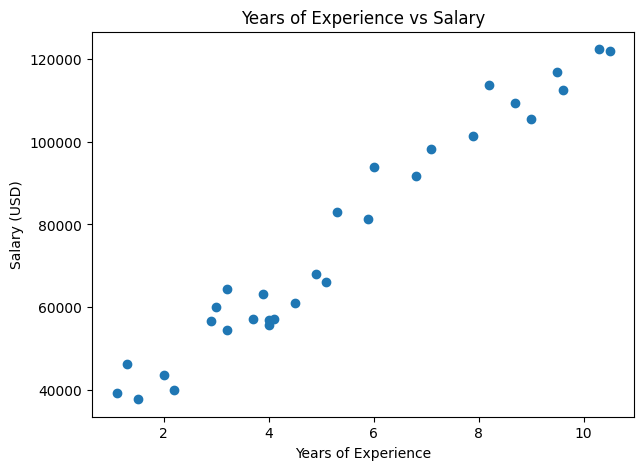

In [10]:
# Step 9: Scatter plot of the actual data
plt.figure(figsize=(7, 5))
plt.scatter(df["YearsExperience"], df["Salary"])
plt.title("Years of Experience vs Salary")
plt.xlabel("Years of Experience")
plt.ylabel("Salary (USD)")
plt.show()

## Step 10 — Plot Regression Line (Train Set)
**Task:** Plot training points and regression line.

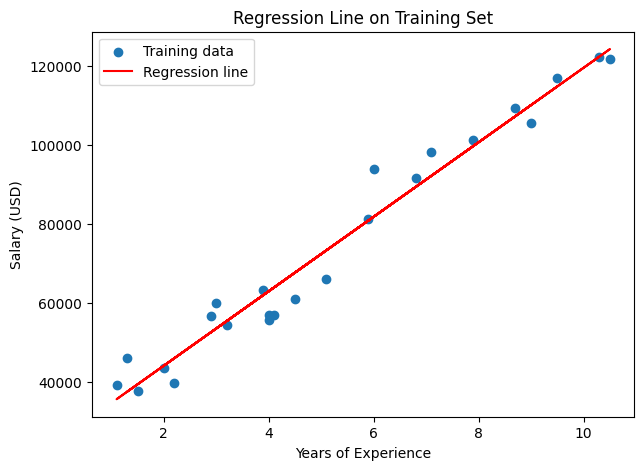

In [11]:
# Step 10: Training points with the fitted regression line
plt.figure(figsize=(7, 5))
plt.scatter(X_train["YearsExperience"], y_train, label="Training data")

y_train_line = model.predict(X_train)
plt.plot(X_train["YearsExperience"], y_train_line, color="red", label="Regression line")

plt.title("Regression Line on Training Set")
plt.xlabel("Years of Experience")
plt.ylabel("Salary (USD)")
plt.legend()
plt.show()

## Step 11 — Plot Regression Line (Test Set)
**Task:** Plot test points and regression line (sorted X for a clean line).

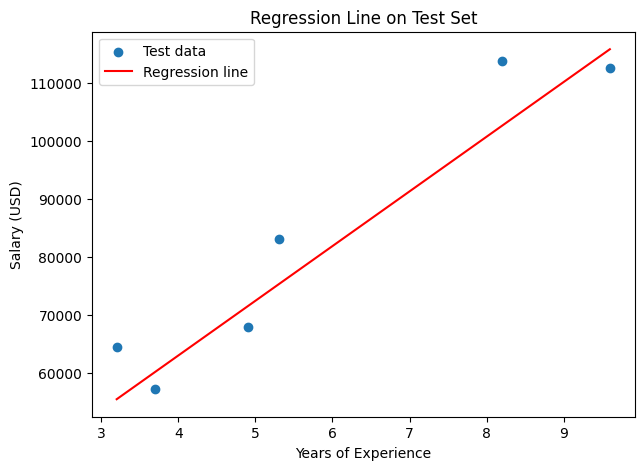

In [12]:
# Step 11: Test points with the regression line (X sorted so the line is clean)
plt.figure(figsize=(7, 5))
plt.scatter(X_test["YearsExperience"], y_test, label="Test data")

X_line = X_test.sort_values(by="YearsExperience")
y_line = model.predict(X_line)

plt.plot(X_line["YearsExperience"], y_line, color="red", label="Regression line")

plt.title("Regression Line on Test Set")
plt.xlabel("Years of Experience")
plt.ylabel("Salary (USD)")
plt.legend()
plt.show()

## Step 12 — Residual Plot (Optional)
**Task:** Compute residuals and plot residuals vs predicted values.

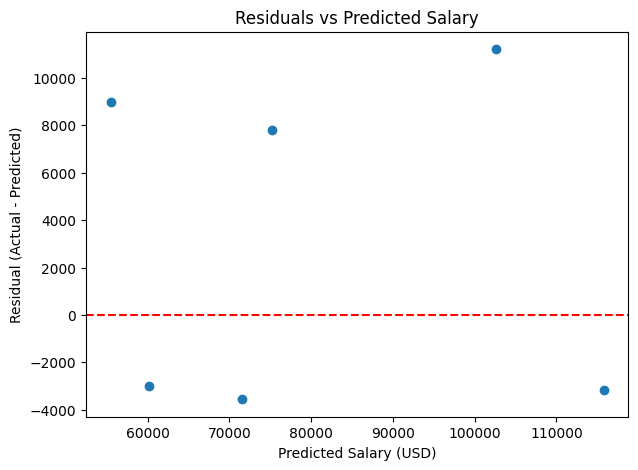

In [13]:
# Step 12: Residual plot (residual = actual - predicted)
residuals = y_test - y_pred

plt.figure(figsize=(7, 5))
plt.scatter(y_pred, residuals)
plt.axhline(0, color="red", linestyle="--")   # zero-error reference line
plt.title("Residuals vs Predicted Salary")
plt.xlabel("Predicted Salary (USD)")
plt.ylabel("Residual (Actual - Predicted)")
plt.show()

# Mini Exercises (Write Your Answers)
**Exercise A:** What does the slope represent in this dataset?

**Exercise B:** If the model has a high R², what does it indicate?

**Exercise C:** How can outliers affect the regression line?


In [14]:
# Exercise A:
# The slope (coefficient) is the average change in salary for each additional year of
# experience. Here it is roughly $9,400 more salary per extra year, holding the model fixed.

# Exercise B:
# A high R^2 (close to 1) means the model explains most of the variation in salary using
# years of experience, so predictions fit the actual values well. It does not by itself prove
# causation or that the model will generalize to new data.

# Exercise C:
# Outliers can pull the regression line toward them because least squares minimizes squared
# errors, so a few extreme points can change the slope and intercept, inflate error metrics
# such as RMSE, and lower R^2.

# Extension Challenge (Optional)
1. Change the test size (example: 0.2 → 0.3)
2. Retrain the model and compare evaluation metrics
3. Write your conclusion in 2–3 lines


In [15]:
# Extension: retrain with test_size=0.3 and compare against test_size=0.2
results = {}
for ts in [0.2, 0.3]:
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=ts, random_state=42)
    m = LinearRegression().fit(Xtr, ytr)
    p = m.predict(Xte)
    results[f"test_size={ts}"] = {
        "MAE": mean_absolute_error(yte, p),
        "MSE": mean_squared_error(yte, p),
        "RMSE": np.sqrt(mean_squared_error(yte, p)),
        "R^2": r2_score(yte, p),
    }
pd.DataFrame(results)

# Conclusion (see markdown cell below)

,test_size=0.2,test_size=0.3
MAE,6.286454e+03,5.161329e+03
MSE,4.983010e+07,3.778466e+07
RMSE,7.059044e+03,6.146923e+03
R^2,9.024462e-01,9.414466e-01


**Conclusion:** With test_size=0.2 the model reached R² = 0.902 (RMSE ≈ $7,059); with test_size=0.3 it reached R² = 0.941 (RMSE ≈ $6,147). Both are strong fits, confirming salary is closely linear in years of experience. Metrics shift slightly because the test set is small (6 vs 9 rows) and different rows are evaluated, and a larger test set trains on less data. A bigger test set gives a more reliable estimate of performance, while a smaller one leaves more data for training.